In [3]:

import pandas as pd
import matplotlib.pyplot as plt

# Load original transaction-level dataset
df = pd.read_excel("../data/raw/Coffee Shop Sales.xlsx")

# Inspect the data
print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nFirst five rows:")
print(df.head())

# Inspect missing values and data types
print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (149116, 11)

Column names: ['transaction_id', 'transaction_date', 'transaction_time', 'transaction_qty', 'store_id', 'store_location', 'product_id', 'unit_price', 'product_category', 'product_type', 'product_detail']

First five rows:
   transaction_id transaction_date transaction_time  transaction_qty  \
0               1       2023-01-01         07:06:11                2   
1               2       2023-01-01         07:08:56                2   
2               3       2023-01-01         07:14:04                2   
3               4       2023-01-01         07:20:24                1   
4               5       2023-01-01         07:22:41                2   

   store_id   store_location  product_id  unit_price    product_category  \
0         5  Lower Manhattan          32         3.0              Coffee   
1         5  Lower Manhattan          57         3.1                 Tea   
2         5  Lower Manhattan          59         4.5  Drinking Chocolate   
3         5 

In [5]:
#check missing values
print(df.isnull().sum())

#store locations
print(df["store_location"].value_counts())

#product categories

print(
    df.groupby("product_category")["transaction_qty"]
      .sum()
      .sort_values(ascending=False)
)

#date range

df["transaction_date"] = pd.to_datetime(
    df["transaction_date"]
)

print("Start:", df["transaction_date"].min())
print("End:", df["transaction_date"].max())
  

transaction_id      0
transaction_date    0
transaction_time    0
transaction_qty     0
store_id            0
store_location      0
product_id          0
unit_price          0
product_category    0
product_type        0
product_detail      0
dtype: int64
store_location
Hell's Kitchen     50735
Astoria            50599
Lower Manhattan    47782
Name: count, dtype: int64
product_category
Coffee                89250
Tea                   69737
Bakery                23214
Drinking Chocolate    17457
Flavours              10511
Coffee beans           1828
Loose Tea              1210
Branded                 776
Packaged Chocolate      487
Name: transaction_qty, dtype: int64
Start: 2023-01-01 00:00:00
End: 2023-06-30 00:00:00


In [6]:
#filter beverage transactions
beverage_categories = [
    "Coffee",
    "Tea",
    "Drinking Chocolate"
]

drinks_df = df[
    df["product_category"].isin(beverage_categories)
].copy()

print("Beverage transaction records:", len(drinks_df))
print("Total drinks sold:", drinks_df["transaction_qty"].sum())

Beverage transaction records: 115333
Total drinks sold: 176444


In [7]:
#extract the hour, group them into hourly intervals
drinks_df["hour"] = pd.to_timedelta(
    drinks_df["transaction_time"].astype(str)
).dt.components.hours

print(drinks_df[
    ["transaction_time", "hour"]
].head())

#aggregate transactions by hour
hourly_df = (
    drinks_df.groupby(
        ["transaction_date", "store_location", "hour"],
        as_index=False
    )["transaction_qty"]
    .sum()
    .rename(columns={
        "transaction_qty": "drinks_sold"
    })
)

print(hourly_df.head(10))
print("Hourly observations:", len(hourly_df))

  transaction_time  hour
0         07:06:11     7
1         07:08:56     7
2         07:14:04     7
3         07:20:24     7
4         07:22:41     7
  transaction_date  store_location  hour  drinks_sold
0       2023-01-01         Astoria    11           28
1       2023-01-01         Astoria    12           38
2       2023-01-01         Astoria    13           30
3       2023-01-01         Astoria    14           21
4       2023-01-01         Astoria    15           28
5       2023-01-01         Astoria    16           32
6       2023-01-01         Astoria    17           21
7       2023-01-01         Astoria    18           35
8       2023-01-01         Astoria    19           27
9       2023-01-01  Hell's Kitchen     8           12
Hourly observations: 6862


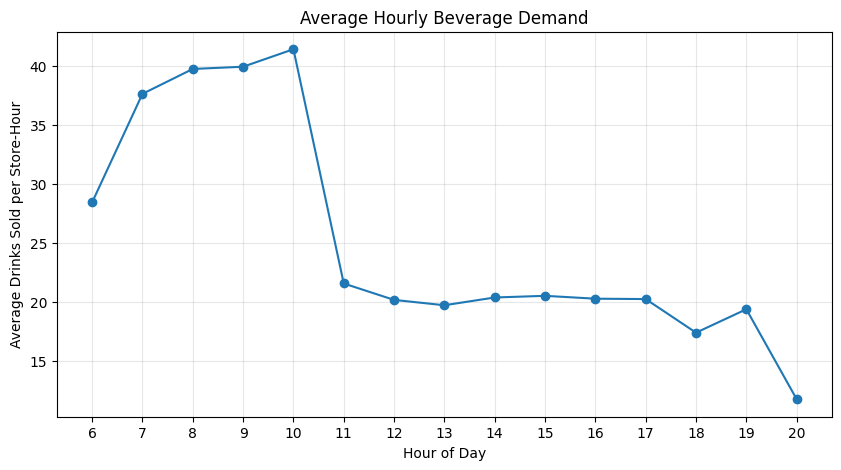

In [8]:
#first visualization (see which hours tend to be busiest)
avg_hourly_demand = (
    hourly_df.groupby("hour")["drinks_sold"]
    .mean()
)

plt.figure(figsize=(10, 5))

plt.plot(
    avg_hourly_demand.index,
    avg_hourly_demand.values,
    marker="o"
)

plt.title("Average Hourly Beverage Demand")
plt.xlabel("Hour of Day")
plt.ylabel("Average Drinks Sold per Store-Hour")
plt.xticks(avg_hourly_demand.index)
plt.grid(alpha=0.3)

plt.show()

Morning demand is highest, sales rise sharply between 6-8 AM
10 AM is the peak, with approx. 41-42 drinks sold per observed store-hour
Demand decreases significantly at 11 AM, dropping to approx. 22 drinks
Afternoond demand is relatively stable, averaging around 20 drinks per observed store-hour.

In [9]:
#graph shows a nearly 50% drop in demand after 10am, with a small uptick around 2pm. Demand is lowest after 5pm.
#check how many observations we have for each hour, and the min/max drinks sold per hour
hourly_summary = (
    hourly_df.groupby("hour")["drinks_sold"]
    .agg(["mean", "count", "min", "max"])
    .round(2)
)

print(hourly_summary.to_string())

       mean  count  min  max
hour                        
6     28.43    190    4   79
7     37.62    412    6   90
8     39.73    507   10  141
9     39.92    507    4  119
10    41.40    507    8  127
11    21.55    543    2   86
12    20.16    542    1   87
13    19.71    536    1   82
14    20.37    537    3   66
15    20.51    536    1   78
16    20.26    537    1   67
17    20.23    536    1   68
18    17.39    535    1   68
19    19.37    378    1   71
20    11.75     59    1   33


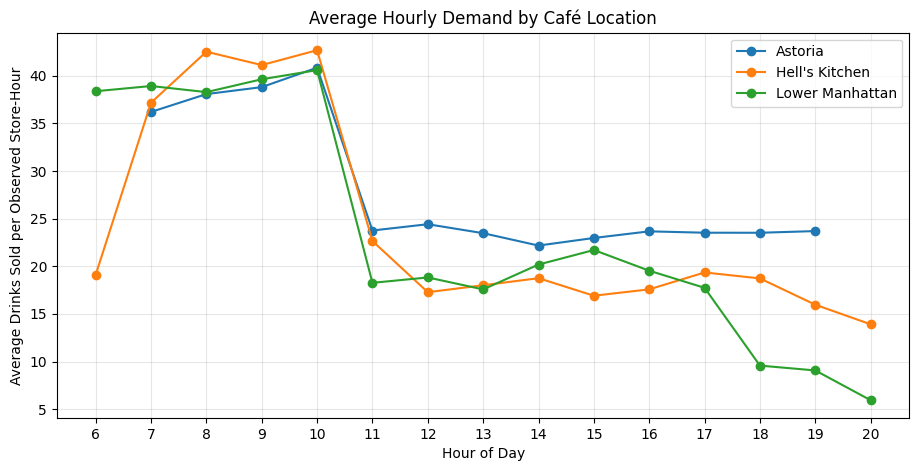

In [10]:
#compare cafe locations
store_hourly = (
    hourly_df.groupby(
        ["store_location", "hour"]
    )["drinks_sold"]
    .mean()
    .unstack(0)
)

plt.figure(figsize=(11, 5))

for store in store_hourly.columns:
    plt.plot(
        store_hourly.index,
        store_hourly[store],
        marker="o",
        label=store
    )

plt.title("Average Hourly Demand by Café Location")
plt.xlabel("Hour of Day")
plt.ylabel("Average Drinks Sold per Observed Store-Hour")
plt.xticks(store_hourly.index)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Should include both hour and store_location as predictive features. Their interaction may also matter, since demand changes differently by location throughout the day.

In [11]:
#check which hours each location has data for
hour_counts = pd.crosstab(
    hourly_df["hour"],
    hourly_df["store_location"]
)

print(hour_counts.to_string())

store_location  Astoria  Hell's Kitchen  Lower Manhattan
hour                                                    
6                     0              98               92
7                   133              98              181
8                   145             181              181
9                   145             181              181
10                  145             181              181
11                  181             181              181
12                  180             181              181
13                  181             181              174
14                  181             181              175
15                  180             181              175
16                  181             181              175
17                  181             181              174
18                  181             181              173
19                  181             181               16
20                    0              43               16


Missing store-hours shouldn't automatically be treated as zero sales. A closed store is different from an open store with zero customers.

In [12]:
#create weekday/weekend indicator for each observation
hourly_df["day_of_week"] = (
    hourly_df["transaction_date"].dt.dayofweek
)

hourly_df["is_weekend"] = (
    hourly_df["day_of_week"] >= 5
)

print(hourly_df.head())

  transaction_date store_location  hour  drinks_sold  day_of_week  is_weekend
0       2023-01-01        Astoria    11           28            6        True
1       2023-01-01        Astoria    12           38            6        True
2       2023-01-01        Astoria    13           30            6        True
3       2023-01-01        Astoria    14           21            6        True
4       2023-01-01        Astoria    15           28            6        True


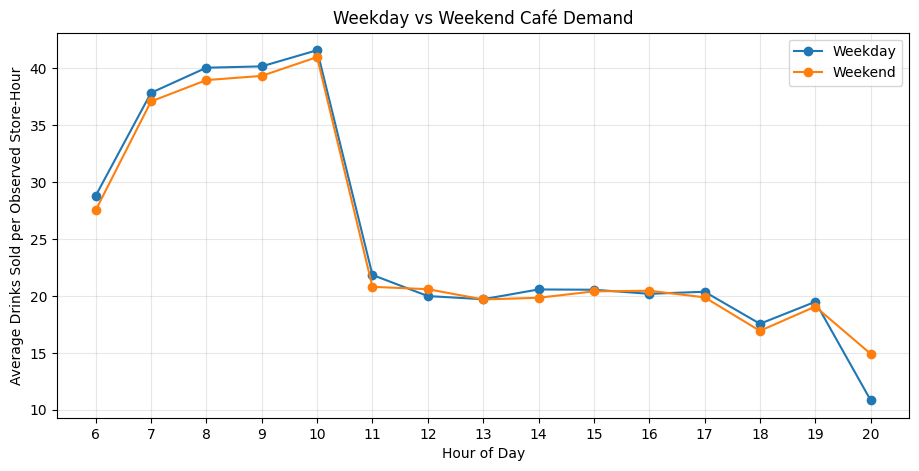

In [13]:
#compare weekend vs weekday demand
weekend_demand = (
    hourly_df.groupby(
        ["hour", "is_weekend"]
    )["drinks_sold"]
    .mean()
    .unstack()
)

plt.figure(figsize=(11, 5))

plt.plot(
    weekend_demand.index,
    weekend_demand[False],
    marker="o",
    label="Weekday"
)

plt.plot(
    weekend_demand.index,
    weekend_demand[True],
    marker="o",
    label="Weekend"
)

plt.title("Weekday vs Weekend Café Demand")
plt.xlabel("Hour of Day")
plt.ylabel("Average Drinks Sold per Observed Store-Hour")
plt.xticks(weekend_demand.index)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

Whether a day is a weekday or weekend may be less important than the hour of day for predicting demand in this dataset

In [ ]:
#investigate the 10AM to 11AM drop in demand
morning = hourly_df[
    hourly_df["hour"].isin([10, 11])
].pivot(
    index=["transaction_date", "store_location"],
    columns="hour",
    values="drinks_sold"
)

#only compare dates where both hours exist
morning = morning.dropna(subset=[10, 11])
morning["change"] = morning[11] - morning[10]

print(
    morning.groupby("store_location")[
        [10, 11, "change"]
    ].mean().round(2)
)

hour                10     11  change
store_location                       
Astoria          40.84  20.57  -20.28
Hell's Kitchen   42.67  22.65  -20.03
Lower Manhattan  40.59  18.26  -22.33


In [15]:
morning = (
    hourly_df[
        hourly_df["hour"].isin([10, 11])
    ]
    .pivot(
        index=["transaction_date", "store_location"],
        columns="hour",
        values="drinks_sold"
    )
    .dropna(subset=[10, 11])
)

summary = morning.groupby(level="store_location")[
    [10, 11]
].mean()

summary["drop_pct"] = (
    (summary[10] - summary[11]) / summary[10] * 100
)

summary["matched_days"] = morning.groupby(
    level="store_location"
).size()

print(summary.round(2).to_string())

hour                10     11  drop_pct  matched_days
store_location                                       
Astoria          40.84  20.57     49.65           145
Hell's Kitchen   42.67  22.65     46.93           181
Lower Manhattan  40.59  18.26     55.01           181


All three locations experience a roughly 47–55% decline in recorded beverage sales after 10 AM, even when comparing the same stores on the same dates.
Hour of day is likely an important predictive feature, store location matters because the magnitude of the decline differs.
The ML model needs to capture a sharp, nonlinear change in demand

In [25]:
# Recreate features_df from the original hourly data
features_df = hourly_df[
    ["transaction_date", "store_location", "hour", "drinks_sold"]
].copy()

# Add calendar features
features_df["day_of_week"] = (
    features_df["transaction_date"].dt.dayofweek
)

features_df["is_weekend"] = (
    features_df["day_of_week"] >= 5
).astype(int)

features_df["month"] = (
    features_df["transaction_date"].dt.month
)

In [26]:
#create historical sales features for modeling
for days in [1, 7]:
    previous = hourly_df[
        ["transaction_date", "store_location", "hour", "drinks_sold"]
    ].copy()

    previous["transaction_date"] += pd.Timedelta(days=days)

    previous = previous.rename(
        columns={"drinks_sold": f"sales_lag_{days}d"}
    )

    features_df = features_df.merge(
        previous,
        on=["transaction_date", "store_location", "hour"],
        how="left",
        validate="one_to_one"
    )

print(features_df.head(10))
print("\nMissing lag values:")
print(
    features_df[
        ["sales_lag_1d", "sales_lag_7d"]
    ].isna().sum()
)

  transaction_date  store_location  hour  drinks_sold  day_of_week  \
0       2023-01-01         Astoria    11           28            6   
1       2023-01-01         Astoria    12           38            6   
2       2023-01-01         Astoria    13           30            6   
3       2023-01-01         Astoria    14           21            6   
4       2023-01-01         Astoria    15           28            6   
5       2023-01-01         Astoria    16           32            6   
6       2023-01-01         Astoria    17           21            6   
7       2023-01-01         Astoria    18           35            6   
8       2023-01-01         Astoria    19           27            6   
9       2023-01-01  Hell's Kitchen     8           12            6   

   is_weekend  month  sales_lag_1d  sales_lag_7d  
0           1      1           NaN           NaN  
1           1      1           NaN           NaN  
2           1      1           NaN           NaN  
3           1      1     

In [29]:
# Start fresh every time
features_df = hourly_df[
    ["transaction_date", "store_location", "hour", "drinks_sold"]
].copy()

# Calendar features
features_df["day_of_week"] = (
    features_df["transaction_date"].dt.dayofweek
)

features_df["is_weekend"] = (
    features_df["day_of_week"] >= 5
).astype(int)

features_df["month"] = (
    features_df["transaction_date"].dt.month
)

# Historical sales features
for days in [1, 7]:
    previous = hourly_df[
        ["transaction_date", "store_location", "hour", "drinks_sold"]
    ].copy()

    previous["transaction_date"] += pd.Timedelta(days=days)

    previous = previous.rename(
        columns={"drinks_sold": f"sales_lag_{days}d"}
    )

    features_df = features_df.merge(
        previous,
        on=["transaction_date", "store_location", "hour"],
        how="left",
        validate="one_to_one"
    )

# Verify
print("Columns:", features_df.columns.tolist())
print("\nMissing values:")
print(features_df.isna().sum())
print("\nShape:", features_df.shape)

Columns: ['transaction_date', 'store_location', 'hour', 'drinks_sold', 'day_of_week', 'is_weekend', 'month', 'sales_lag_1d', 'sales_lag_7d']

Missing values:
transaction_date      0
store_location        0
hour                  0
drinks_sold           0
day_of_week           0
is_weekend            0
month                 0
sales_lag_1d        233
sales_lag_7d        559
dtype: int64

Shape: (6862, 9)


In [30]:
# Keep rows where both lag values exist
model_df = features_df.dropna(
    subset=["sales_lag_1d", "sales_lag_7d"]
).copy()

print("Original observations:", len(features_df))
print("Usable observations:", len(model_df))
print("Removed observations:", len(features_df) - len(model_df))

print("\nRemaining missing values:")
print(model_df.isna().sum())

Original observations: 6862
Usable observations: 6164
Removed observations: 698

Remaining missing values:
transaction_date    0
store_location      0
hour                0
drinks_sold         0
day_of_week         0
is_weekend          0
month               0
sales_lag_1d        0
sales_lag_7d        0
dtype: int64


In [31]:
#verify the final feature dataset:
print(
    model_df[
        [
            "transaction_date",
            "store_location",
            "hour",
            "day_of_week",
            "is_weekend",
            "month",
            "sales_lag_1d",
            "sales_lag_7d",
            "drinks_sold"
        ]
    ].head(10).to_string(index=False)
)

transaction_date store_location  hour  day_of_week  is_weekend  month  sales_lag_1d  sales_lag_7d  drinks_sold
      2023-01-08        Astoria    11            6           1      1          17.0          28.0           14
      2023-01-08        Astoria    12            6           1      1          26.0          38.0           13
      2023-01-08        Astoria    13            6           1      1          18.0          30.0           20
      2023-01-08        Astoria    14            6           1      1          12.0          21.0           16
      2023-01-08        Astoria    15            6           1      1          18.0          28.0           15
      2023-01-08        Astoria    16            6           1      1          11.0          32.0            7
      2023-01-08        Astoria    17            6           1      1           7.0          21.0           11
      2023-01-08        Astoria    18            6           1      1          30.0          35.0           13
 

In [32]:
model_df.to_csv("../data/processed/model_data.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [33]:

from pathlib import Path

#save the complete hourly dataset
hourly_df.to_csv(
    "../data/processed/hourly_sales.csv",
    index=False
)

print("Saved successfully!")
print("Shape:", hourly_df.shape)


Saved successfully!
Shape: (6862, 6)
